# Telecom Customer Churn: End-to-End Problem Formulation & ML Pipeline

## 1. Scenario & Business Objective
In a subscription-based telecommunications business, retaining existing subscribers is significantly more cost-effective than acquiring new ones. However, customer churn often begins merely as a loose business inquiry: **"Which customers are at risk of leaving?"**

To solve this algorithmically, we must:
1. **Formulate the ML Task**: Frame the business inquiry as a Supervised Binary Classification task.
2. **Feature Engineering**: Select behavioral and demographic features ($X$).
3. **Domain-Driven Label Construction**: Derive ground-truth churn labels ($y$) based on operational business rules.
4. **Data Validation & Class Balance**: Audit tensor dimensions and quantify class imbalance.
5. **Exploratory Data Analysis (EDA)**: Visualize the churn distribution.
6. **Modular Implementation**: Transition from notebook prototyping into an executable Python package.

--- 
## 2. Import Core Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set seed for absolute reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print("Libraries loaded successfully.")

Libraries loaded successfully.


--- 
## 3. Synthetic Customer Ingestion

We simulate account attributes for $N=100$ customers:
- `age`: Customer age in years (18 to 60)
- `monthly_charges`: Current bill in USD ($20 to $120)
- `tenure`: Length of active service in months (1 to 60)
- `contract_type`: `0` = Month-to-month, `1` = Long-term annual

In [3]:
n_samples = 100

raw_data = pd.DataFrame({
    "age": np.random.randint(18, 60, n_samples),
    "monthly_charges": np.random.randint(20, 120, n_samples),
    "tenure": np.random.randint(1, 60, n_samples),
    "contract_type": np.random.choice([0, 1], n_samples)
})

print(f"Raw dataset shape: {raw_data.shape}")
raw_data.head()

Raw dataset shape: (100, 4)


,age,monthly_charges,tenure,contract_type
0,56,92,54,1
1,46,91,23,1
2,32,31,37,1
3,25,53,32,1
4,38,52,33,0


--- 
## 4. Business Logic Formulation (Label Engineering)

### Domain Rule
Subscribers are categorized into the **high churn risk cohort** if they experience high financial friction early in their customer lifecycle before brand loyalty develops:

$$\text{churn} = (\text{monthly\_charges} > 80) \;\mathbf{AND}\; (\text{tenure} < 20)$$

- **`1` (Churned)**: At-risk customer.
- **`0` (Retained)**: Loyal or low-cost customer.

In [4]:
MONTHLY_CHARGES_THRESHOLD = 80.0
TENURE_THRESHOLD = 20

churn_condition = (
    (raw_data["monthly_charges"] > MONTHLY_CHARGES_THRESHOLD) &
    (raw_data["tenure"] < TENURE_THRESHOLD)
)

raw_data["churn"] = churn_condition.astype(int)
raw_data.head(10)

,age,monthly_charges,tenure,contract_type,churn
0,56,92,54,1,0
1,46,91,23,1,0
2,32,31,37,1,0
3,25,53,32,1,0
4,38,52,33,0,0
5,56,67,1,1,0
6,36,42,19,1,0
7,40,81,2,0,1
8,28,107,53,0,0
9,28,56,44,0,0


--- 
## 5. Dataset Audit & Structural Statistics

In [5]:
print("=== Data Schema ===")
raw_data.info()

print("\n=== Descriptive Statistics ===")
raw_data.describe()

=== Data Schema ===
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              100 non-null    int64
 1   monthly_charges  100 non-null    int64
 2   tenure           100 non-null    int64
 3   contract_type    100 non-null    int64
 4   churn            100 non-null    int64
dtypes: int64(5)
memory usage: 4.0 KB

=== Descriptive Statistics ===


,age,monthly_charges,tenure,contract_type,churn
count,100.000000,100.000000,100.00000,100.000000,100.000000
mean,37.910000,69.270000,29.43000,0.520000,0.130000
std,12.219454,29.842636,17.87287,0.502117,0.337998
min,18.000000,20.000000,1.00000,0.000000,0.000000
25%,26.750000,46.750000,16.00000,0.000000,0.000000
50%,38.000000,70.500000,30.50000,1.000000,0.000000
75%,46.250000,94.500000,45.00000,1.000000,0.000000
max,59.000000,118.000000,59.00000,1.000000,1.000000


--- 
## 6. Feature Matrix ($X$) & Target Vector ($y$) Separation

In [6]:
feature_cols = ["age", "monthly_charges", "tenure", "contract_type"]
target_col = "churn"

X =raw_data[feature_cols].copy()
y = raw_data[target_col].copy()

print("Features (X) Head:")
display(X.head())

print("Target (y) Head:")
display(y.head())

Features (X) Head:


,age,monthly_charges,tenure,contract_type
0,56,92,54,1
1,46,91,23,1
2,32,31,37,1
3,25,53,32,1
4,38,52,33,0


Target (y) Head:


0    0
1    0
2    0
3    0
4    0
Name: churn, dtype: int64

--- 
## 7. ML Task Formalization & Imbalance Verification

In [9]:
def validate_ml_task(X: pd.DataFrame, y: pd.Series) -> None:
    """Validates tensor dimensions and reports class distribution."""
    print("--- ML Task Formalization ---")
    print("Task Type: Binary Classification")
    print(f"Feature Matrix Shape (X): {X.shape}")
    print(f"Target Vector Shape (y):  {y.shape}")
    
    # Row count verification
    assert X.shape[0] == y.shape[0], "Dimension mismatch between X and y!"

    print("\n--- Target Class Balance ---")
    counts = y.value_counts()
    percentages = y.value_counts(normalize=True) * 100
    balance_df = pd.DataFrame({"Count": counts, "Percentage (%)": percentages.round(2)})
    print(balance_df)

validate_ml_task(X, y)

--- ML Task Formalization ---
Task Type: Binary Classification
Feature Matrix Shape (X): (100, 4)
Target Vector Shape (y):  (100,)

--- Target Class Balance ---
       Count  Percentage (%)
churn                       
0         87            87.0
1         13            13.0


--- 
## 8. Target Class Visual Analysis

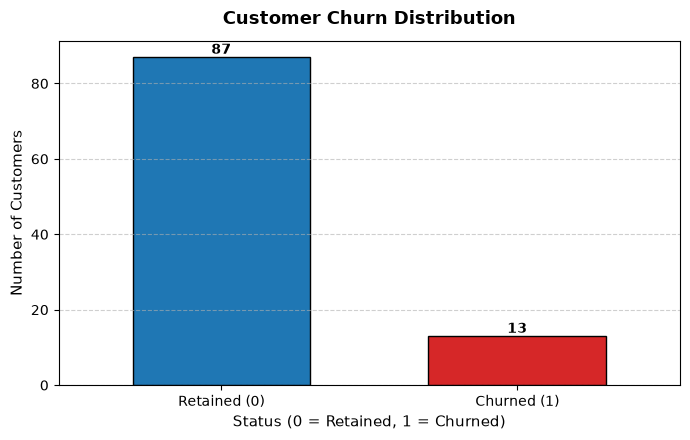

In [10]:
plt.figure(figsize=(7, 4.5))
ax = y.value_counts().plot(
    kind="bar",
    color=["#1f77b4", "#d62728"],
    edgecolor="black",
    width=0.6
)

plt.title("Customer Churn Distribution", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Status (0 = Retained, 1 = Churned)", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.xticks(ticks=[0, 1], labels=["Retained (0)", "Churned (1)"], rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Label bar tops
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()